# Modularity on the Karate Club Graph (DSC212)
Recursive spectral modularity partitioning implemented from scratch (NumPy + NetworkX), following Newman (2006), *Modularity and community structure in networks*, PNAS 103(23):8577-8582.

**Plan:** build $B = A - kk^\top/2m$ -> leading eigenvector -> split by sign -> recurse while $\lambda_1>0$ -> visualise every split -> track degree / betweenness / closeness / clustering per node across iterations.

In [1]:
import numpy as np, networkx as nx, matplotlib.pyplot as plt
from collections import deque
plt.rcParams['figure.dpi']=110

G = nx.karate_club_graph()          # nodes 0..33 ; 0 = Mr. Hi, 33 = Officer (president)
n, m = G.number_of_nodes(), G.number_of_edges()
nodes = list(G.nodes())
A = nx.to_numpy_array(G, nodelist=nodes, weight=None)   # unweighted, as in the handout
k = A.sum(axis=1)
B = A - np.outer(k, k)/(2*m)
print(n, m, np.allclose(B, B.T), np.allclose(B@np.ones(n), 0))   # Prop.1 and Prop.2 checks
pos = nx.spring_layout(G, seed=42)  # FIXED layout reused for every figure
truth = {i: G.nodes[i]['club'] for i in nodes}   # 'Mr. Hi' / 'Officer' ground truth

34 78 True True


## 1. Spectral bisection of one group $C$
Uses $B^{(C)}$ = block of $B$ on $C$ exactly as in the handout (`generalized=False`). Newman's *generalised* matrix (diagonal correction $B^{(C)}_{ij}-\delta_{ij}\sum_{l\in C}B_{il}$) is also available (`generalized=True`) and is compared at the end.

In [2]:
def split_group(Cnodes, generalized=False, tol=1e-10):
    idx = np.array(Cnodes)
    BC = B[np.ix_(idx, idx)].copy()
    if generalized:
        BC -= np.diag(BC.sum(axis=1))
    vals, vecs = np.linalg.eigh(BC)          # ascending, symmetric matrix
    lam, u = vals[-1], vecs[:, -1]
    if lam <= tol:
        return None, lam
    s = np.where(u > 0, 1, -1)
    Cp, Cm = idx[s == 1].tolist(), idx[s == -1].tolist()
    if len(Cp)==0 or len(Cm)==0:
        return None, lam
    return (Cp, Cm), lam

def Q_of(partition):
    return nx.community.modularity(G, [set(c) for c in partition], weight=None)

def recursive_bisection(generalized=False):
    queue = deque([list(nodes)])
    final, history = [], []
    snapshot = lambda: [sorted(c) for c in final] + [sorted(c) for c in queue]
    history.append(dict(partition=snapshot(), lam=None, note='start: whole graph'))
    while queue:
        Cn = queue.popleft()
        res, lam = split_group(Cn, generalized)
        if res is None:
            final.append(Cn)
            print(f'group of {len(Cn):2d} nodes is indivisible (lambda1={lam:.4f})')
        else:
            queue.extend(res)
            history.append(dict(partition=snapshot(), lam=lam, note=f'split group of {len(Cn)} (lambda1={lam:.3f})'))
            print(f'split group of {len(Cn):2d} nodes (lambda1={lam:.4f}) -> sizes {len(res[0])}, {len(res[1])}')
    return final, history

final, history = recursive_bisection(generalized=False)
for it,h in enumerate(history):
    h['Q'] = Q_of(h['partition'])
    print(f"iter {it}: {len(h['partition'])} communities, Q = {h['Q']:.4f}")

split group of 34 nodes (lambda1=4.9771) -> sizes 16, 18
split group of 16 nodes (lambda1=2.9441) -> sizes 10, 6
split group of 18 nodes (lambda1=2.5041) -> sizes 5, 13
group of 10 nodes is indivisible (lambda1=2.5712)
split group of  6 nodes (lambda1=2.1480) -> sizes 1, 5
group of  5 nodes is indivisible (lambda1=1.8759)
group of 13 nodes is indivisible (lambda1=2.3563)
group of  1 nodes is indivisible (lambda1=-0.0064)
group of  5 nodes is indivisible (lambda1=2.1470)
iter 0: 1 communities, Q = 0.0000
iter 1: 2 communities, Q = 0.3715
iter 2: 3 communities, Q = 0.3898
iter 3: 4 communities, Q = 0.4081
iter 4: 5 communities, Q = 0.4094


## 2. Visualisation after every split (fixed layout, one colour per community, node IDs shown)

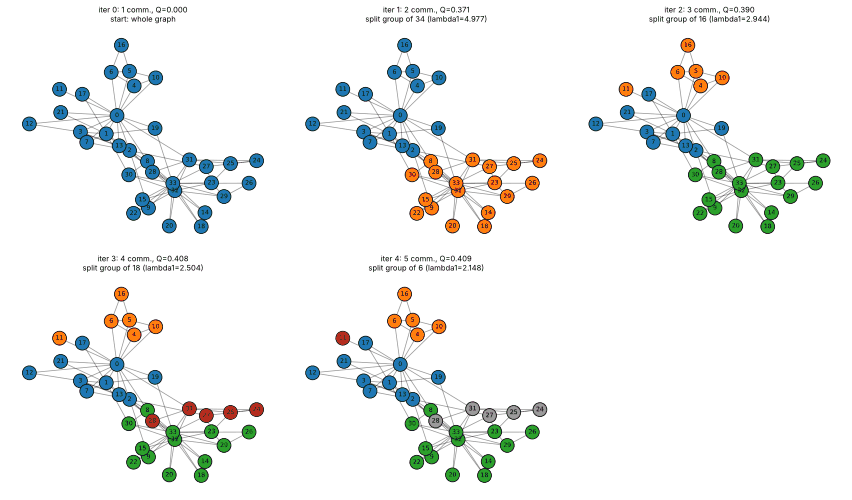

In [3]:
cmap = plt.cm.tab10
def draw(partition, title, ax):
    col = {}
    for ci,c in enumerate(sorted(partition, key=lambda c: min(c))):
        for v in c: col[v]=cmap(ci%10)
    nx.draw_networkx_edges(G, pos, ax=ax, alpha=.4)
    nx.draw_networkx_nodes(G, pos, node_color=[col[v] for v in nodes], node_size=330, ax=ax, edgecolors='k')
    nx.draw_networkx_labels(G, pos, font_size=8, ax=ax)
    ax.set_title(title, fontsize=10); ax.axis('off')

cols = 3; rows = int(np.ceil(len(history)/cols))
fig, axes = plt.subplots(rows, cols, figsize=(5.2*cols, 4.6*rows))
for it,(h,ax) in enumerate(zip(history, axes.ravel())):
    draw(h['partition'], f"iter {it}: {len(h['partition'])} comm., Q={h['Q']:.3f}\n{h['note']}", ax)
for ax in axes.ravel()[len(history):]: ax.axis('off')
plt.tight_layout(); plt.show()

## 3. Does the first split recover the real club fission?

In [4]:
first = history[1]['partition']
side = {v:i for i,c in enumerate(first) for v in c}
lab = {'Mr. Hi':0,'Officer':1}
agree = sum(side[v]==lab[truth[v]] for v in nodes)
agree = max(agree, n-agree)
print(f'First split agrees with the real split for {agree}/{n} nodes')
print('Mismatched nodes:', [v for v in nodes if (side[v]==lab[truth[v]]) != (side[0]==lab[truth[0]])])

First split agrees with the real split for 33/34 nodes
Mismatched nodes: [8]


## 4. Node metrics after each split
Because centralities of the *whole* graph never change when we merely relabel communities, we compute each metric **inside the node's own community** (induced subgraph, NetworkX built-ins). Iteration 0 = whole graph, so it is the global baseline; later iterations show how a node looks from within its community.

In [5]:
def metrics_for(partition):
    out = {'degree':{}, 'betweenness':{}, 'closeness':{}, 'clustering':{}}
    for c in partition:
        H = G.subgraph(c)
        if len(c)==1:
            for key in out: out[key][c[0]] = 0.0
            continue
        for key,fn in [('degree',nx.degree_centrality),('betweenness',nx.betweenness_centrality),
                       ('closeness',nx.closeness_centrality),('clustering',nx.clustering)]:
            out[key].update(fn(H))
    return out

metrics = {it: metrics_for(h['partition']) for it,h in enumerate(history)}   # dict keyed by iteration
import pandas as pd
def table(key): return pd.DataFrame({it:[metrics[it][key][v] for v in nodes] for it in metrics}, index=nodes)
tables = {key: table(key) for key in ['degree','betweenness','closeness','clustering']}
tables['degree'].round(3).head(8)

       0      1      2      3      4
0  0.485  0.933  1.000  1.000  1.000
1  0.273  0.533  0.889  0.889  0.889
2  0.303  0.333  0.556  0.556  0.556
3  0.182  0.400  0.667  0.667  0.667
4  0.091  0.200  0.400  0.400  0.500
5  0.121  0.267  0.600  0.600  0.750
6  0.121  0.267  0.600  0.600  0.750
7  0.121  0.267  0.444  0.444  0.444

## 5. Evolution of each metric across iterations

--- degree: top-5 nodes at each iteration
0 [33, 0, 32, 2, 1]
1 [0, 33, 32, 1, 3]
2 [0, 1, 33, 3, 32]
3 [0, 33, 1, 32, 31]
4 [0, 33, 1, 32, 5]
--- betweenness: top-5 nodes at each iteration
0 [0, 33, 32, 2, 31]
1 [0, 33, 32, 31, 1]
2 [33, 0, 1, 32, 5]
3 [33, 24, 31, 0, 32]
4 [33, 24, 31, 0, 32]
--- closeness: top-5 nodes at each iteration
0 [0, 2, 33, 31, 13]
1 [0, 33, 32, 1, 3]
2 [0, 1, 33, 3, 32]
3 [0, 33, 1, 32, 31]
4 [0, 33, 1, 32, 5]
--- clustering: top-5 nodes at each iteration
0 [15, 7, 22, 21, 16]
1 [7, 8, 26, 28, 17]
2 [7, 8, 26, 28, 17]
3 [7, 8, 30, 25, 17]
4 [7, 8, 30, 25, 17]


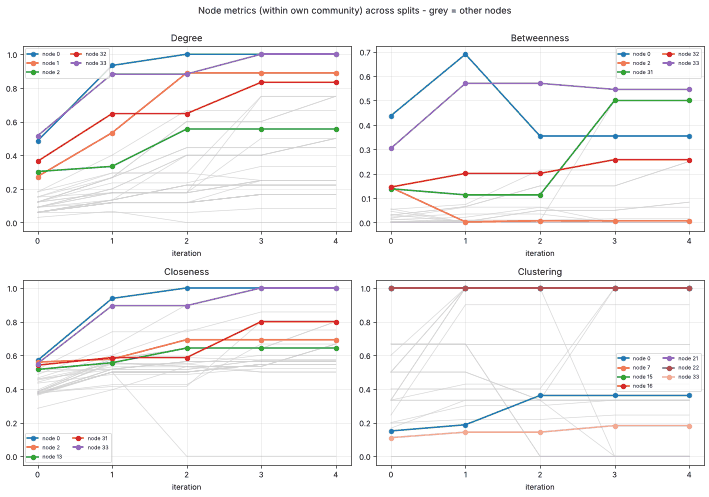

In [6]:
iters = list(metrics)
fig, axes = plt.subplots(2,2, figsize=(13,9))
for ax,(key,df) in zip(axes.ravel(), tables.items()):
    top = df[0].sort_values(ascending=False).index[:5].tolist()   # top-5 globally
    hi = set(top)|{0,33}
    for v in nodes:
        if v not in hi: ax.plot(iters, df.loc[v], color='lightgrey', lw=.8, zorder=1)
    for v in sorted(hi):
        ax.plot(iters, df.loc[v], marker='o', lw=2, label=f'node {v}', zorder=3)
    ax.set_title(key.capitalize()); ax.set_xlabel('iteration'); ax.set_xticks(iters); ax.grid(alpha=.3)
    ax.legend(fontsize=7, ncol=2)
plt.suptitle('Node metrics (within own community) across splits - grey = other nodes', y=1.0)
plt.tight_layout(); plt.show()

for key,df in tables.items():
    print(f'--- {key}: top-5 nodes at each iteration')
    for it in iters: print(it, df[it].sort_values(ascending=False).index[:5].tolist())

## 6. Extra: Q vs. iteration, and handout version vs. Newman's generalised matrix

=== Generalised B^(C) (Newman 2006) ===
split group of 34 nodes (lambda1=4.9771) -> sizes 16, 18
split group of 16 nodes (lambda1=1.1785) -> sizes 7, 9
split group of 18 nodes (lambda1=0.8594) -> sizes 12, 6
group of  7 nodes is indivisible (lambda1=-0.0000)
split group of  9 nodes (lambda1=0.0602) -> sizes 4, 5
group of 12 nodes is indivisible (lambda1=-0.0000)
group of  6 nodes is indivisible (lambda1=0.0000)
group of  4 nodes is indivisible (lambda1=0.0000)
group of  5 nodes is indivisible (lambda1=-0.0000)
Handout version  : 5 communities, Q=0.4094
Generalised      : 5 communities, Q=0.3776
networkx greedy  : Q=0.3807


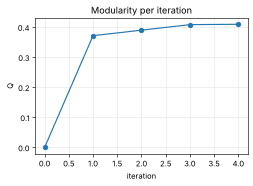

In [7]:
plt.figure(figsize=(5,3.2)); plt.plot(range(len(history)), [h['Q'] for h in history], 'o-')
plt.xlabel('iteration'); plt.ylabel('Q'); plt.title('Modularity per iteration'); plt.grid(alpha=.3); plt.show()

print('=== Generalised B^(C) (Newman 2006) ===')
final_g, hist_g = recursive_bisection(generalized=True)
print('Handout version  : %d communities, Q=%.4f' % (len(final), Q_of(final)))
print('Generalised      : %d communities, Q=%.4f' % (len(final_g), Q_of(final_g)))
print('networkx greedy  : Q=%.4f' % Q_of(nx.community.greedy_modularity_communities(G, weight=None)))

## 7. Discussion
**Method result.** The first spectral split gives communities of 16 and 18 nodes and matches Zachary's real fission for **33 of 34 members**; only node 8 is misplaced (a well-known hard case: he sits between both factions). Recursive bisection then stops at **5 communities with Q = 0.409** (Q: 0 -> 0.372 -> 0.390 -> 0.408 -> 0.409). Q rises with every accepted split, so each split is worthwhile.

**Which nodes stay central.** Nodes **0 (Mr. Hi)** and **33 (the president/Officer)** are in the top-5 for degree and closeness at *every* iteration, and in the top-5 for betweenness at every iteration. Their neighbours **32, 1, 3** appear repeatedly as well. These are the faction leaders, hubs whose influence survives splitting. Node 0 keeps the best closeness throughout; after the later splits, node 33 becomes the top broker and nodes **24 and 31** appear as brokers (betweenness) inside their sub-communities.
For clustering, **7 and 8** (members of tight cliques around Mr. Hi) top the ranking from iteration 1 on, while the high-degree leaders have *low* clustering: hubs connect otherwise unconnected members.

**How community structure shapes the metrics.** (i) Metrics are computed inside each community, so degree and closeness values rise sharply after a split (e.g. node 0's degree centrality goes 0.49 -> 0.93 -> 1.0): the denominator is now the community size, and communities are dense by construction. Raw values across iterations are therefore not directly comparable; *rankings* are the meaningful quantity. (ii) Betweenness reveals bridge nodes inside a group, hidden when looking at the whole graph. (iii) Clustering rises for nodes whose community is nearly a clique.

**Caveat on the stopping rule.** The handout uses the plain block $B^{(C)}$. Newman's generalised matrix subtracts the diagonal term $\sum_{l\in C}B_{il}$, which is what makes the gain $\Delta Q=\frac{1}{4m}s^\top B^{(C)}s$ exact. We ran both (section 6): the handout version ends at Q = 0.409, the generalised version at Q = 0.378, comparable to NetworkX's greedy result (0.381).

*Reference:* M. E. J. Newman (2006), Modularity and community structure in networks, PNAS 103(23):8577-8582.